# 04. Comparação: clássicos x LLM

Tudo na mesma amostra fixa de 200 casos (50 falhas).

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)  # comandos python -m src.* rodam a partir da raiz
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, Markdown, display
from src import config as C
pd.set_option("display.max_columns", 30)

In [2]:
!"{sys.executable}" -m src.compare

# Comparação na amostra fixa de avaliação

Amostra: 200 casos do conjunto de teste (25% falhas). Gerado por `python -m src.compare`.

| stage   | model                  | setting                  |   accuracy |   precision |   recall |    f1 |   roc_auc |   time_per_100_s |   cost_usd |
|:--------|:-----------------------|:-------------------------|-----------:|------------:|---------:|------:|----------:|-----------------:|-----------:|
| I       | mlp                    | balance=smote,engineered |      0.950 |       0.955 |    0.840 | 0.894 |     0.979 |            0.003 |      0.000 |
| I       | rf                     | balance=smote,engineered |      0.945 |       0.954 |    0.820 | 0.882 |     0.976 |            0.105 |      0.000 |
| I       | mlp                    | balance=smote            |      0.945 |       0.976 |    0.800 | 0.879 |     0.979 |            0.002 |      0.000 |
| I       | xgb                    | balance=smote            |      0.945 |       0.976 |    0.

# Comparação na amostra fixa de avaliação

Amostra: 200 casos do conjunto de teste (25% falhas). Gerado por `python -m src.compare`.

| stage   | model                  | setting                  |   accuracy |   precision |   recall |    f1 |   roc_auc |   time_per_100_s |   cost_usd |
|:--------|:-----------------------|:-------------------------|-----------:|------------:|---------:|------:|----------:|-----------------:|-----------:|
| I       | mlp                    | balance=smote,engineered |      0.950 |       0.955 |    0.840 | 0.894 |     0.979 |            0.003 |      0.000 |
| I       | rf                     | balance=smote,engineered |      0.945 |       0.954 |    0.820 | 0.882 |     0.976 |            0.105 |      0.000 |
| I       | mlp                    | balance=smote            |      0.945 |       0.976 |    0.800 | 0.879 |     0.979 |            0.002 |      0.000 |
| I       | xgb                    | balance=smote            |      0.945 |       0.976 |    0.800 | 0.879 |     0.973 |            0.003 |      0.000 |
| I       | xgb                    | balance=smote,engineered |      0.945 |       0.976 |    0.800 | 0.879 |     0.988 |            0.014 |      0.000 |
| I       | xgb                    | balance=class_weight     |      0.945 |       1.000 |    0.780 | 0.876 |     0.970 |            0.003 |      0.000 |
| I       | svm                    | balance=smote            |      0.940 |       0.975 |    0.780 | 0.867 |     0.964 |            0.050 |      0.000 |
| I       | rf                     | balance=smote            |      0.920 |       0.947 |    0.720 | 0.818 |     0.979 |            0.039 |      0.000 |
| I       | svm                    | balance=class_weight     |      0.915 |       0.923 |    0.720 | 0.809 |     0.972 |            0.011 |      0.000 |
| I       | svm                    | balance=smote,engineered |      0.915 |       0.946 |    0.700 | 0.805 |     0.969 |            0.035 |      0.000 |
| I       | rf                     | balance=class_weight     |      0.910 |       1.000 |    0.640 | 0.780 |     0.975 |            0.059 |      0.000 |
| I       | mlp                    | balance=class_weight     |      0.845 |       1.000 |    0.380 | 0.551 |     0.989 |            0.005 |      0.000 |
| II      | deepseek:deepseek-chat | few-shot k=20            |      0.810 |       0.597 |    0.740 | 0.661 |     0.843 |           96.620 |      0.049 |
| II      | deepseek:deepseek-chat | few-shot k=10            |      0.765 |       0.518 |    0.880 | 0.652 |     0.850 |           94.990 |      0.030 |
| II      | deepseek:deepseek-chat | few-shot k=3             |      0.700 |       0.446 |    0.820 | 0.578 |     0.803 |           95.270 |      0.016 |
| II      | deepseek:deepseek-chat | few-shot k=5             |      0.665 |       0.419 |    0.880 | 0.568 |     0.802 |           97.940 |      0.020 |
| II      | deepseek:deepseek-chat | zero-shot                |      0.550 |       0.341 |    0.860 | 0.489 |     0.721 |           97.740 |      0.010 |


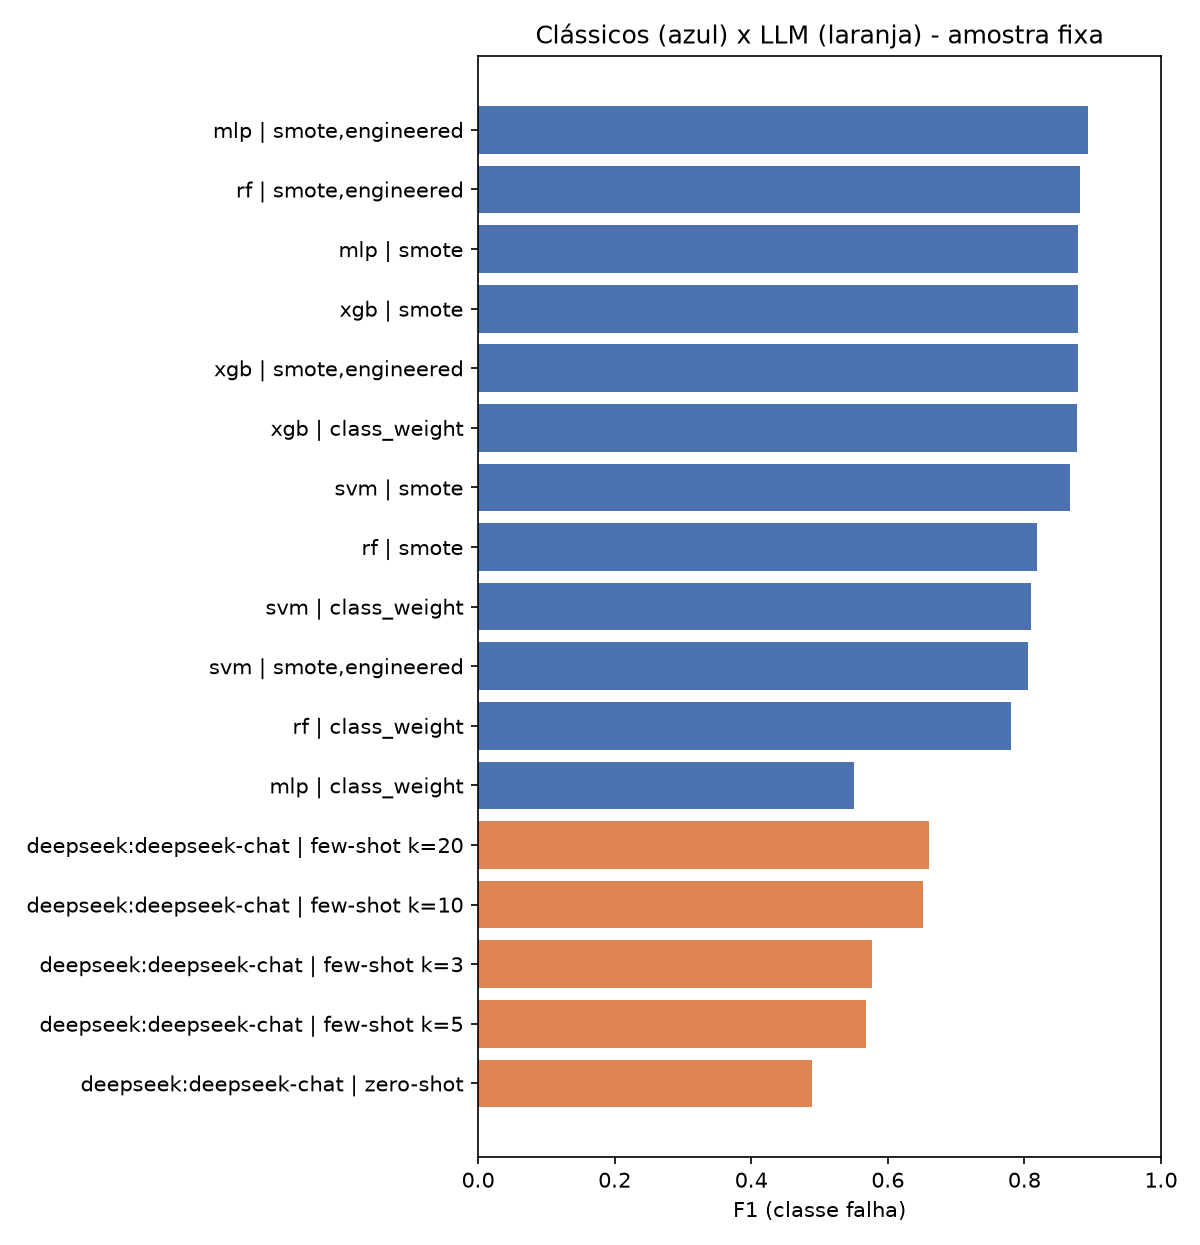

In [3]:
display(Markdown((C.RESULTS / 'comparison.md').read_text(encoding='utf-8')))
display(Image(C.FIGURES / 'comparison_f1.png'))

## Resumo

Configuração principal dos clássicos (SMOTE) contra o LLM (DeepSeek `deepseek-chat`), na amostra fixa.

| Aspecto | Clássicos | LLM |
|---|---|---|
| F1 (classe falha) | 0,82 a 0,88 | 0,49 (zero-shot) a 0,66 (k=20) |
| AUC-ROC | 0,96 a 0,98 | 0,72 a 0,85 |
| Tempo por 100 amostras | menos de 0,1 s | cerca de 95 s |
| Custo por 100 amostras | desprezível (CPU local) | US$ 0,005 a 0,024 |
| Dados rotulados | 8.000 casos de treino | 0 a 20 exemplos no prompt |
| Respostas inválidas | não se aplica | 0 |
| Onde os dados ficam | localmente | enviados a uma API externa |